# 02 · Lee-Carter baseline and a 10-year backtest

**Goal:** fit the classic Lee-Carter model on 1980–2014, forecast 2015–2024, and see how well it did. Before trusting it, compare it with a naive benchmark.

**Model** (written from scratch in `src/lee_carter.py`):

$$\log m_{x,t} = a_x + b_x\,k_t + \varepsilon_{x,t}$$

* $a_x$: the average age shape of mortality
* $k_t$: one number per year for the overall mortality level (falls as mortality improves)
* $b_x$: how much age $x$ moves when $k_t$ moves

$k_t$ is forecast as a random walk with drift. `qx` is converted to a central death rate with $m = -\ln(1-q)$. Ages 0–100 are modelled; StatCan's rates above 100 are smoothed estimates, so I leave them out.

**Benchmark:** a naive model where each age continues its own average log-rate trend over the training years. A complex model should at least beat this.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_qx, qx_matrix, qx_to_mx, mx_to_qx
from src.lee_carter import LeeCarter, random_walk_forecast
from src.evaluate import log_rmse, mape, error_by_year
from src.lifetable import e0

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#999999", "axes.labelcolor": "#333333",
    "xtick.color": "#666666", "ytick.color": "#666666", "lines.linewidth": 2,
})
COLORS = {"male": "#257de0", "female": "#f47230"}
MODEL_COLORS = {"Actual": "#333333", "Lee-Carter": "#257de0", "Naive trend": "#00a080"}
FIG_DIR = "../reports/figures"

TRAIN, TEST = (1980, 2014), (2015, 2024)
H = TEST[1] - TEST[0] + 1

df = load_qx()
q_all = {s: qx_matrix(df, s) for s in ["male", "female"]}
m = {s: qx_to_mx(q_all[s].loc[0:100]) for s in q_all}
train = {s: m[s].loc[:, TRAIN[0]:TRAIN[1]] for s in m}
test = {s: m[s].loc[:, TEST[0]:TEST[1]] for s in m}

lc = {s: LeeCarter().fit(train[s]) for s in m}
for s in lc:
    print(f"{s:6s}  variance explained by first component: {lc[s].explained_variance:.1%}   "
          f"k drift: {lc[s].drift:.2f}/yr   sigma: {lc[s].sigma:.2f}")

male    variance explained by first component: 95.7%   k drift: -2.20/yr   sigma: 1.94
female  variance explained by first component: 92.5%   k drift: -1.55/yr   sigma: 1.65


The single Lee-Carter component explains about 96% (male) and 93% (female) of the variation in log death rates over 1980–2014, so one time index captures most of the movement.

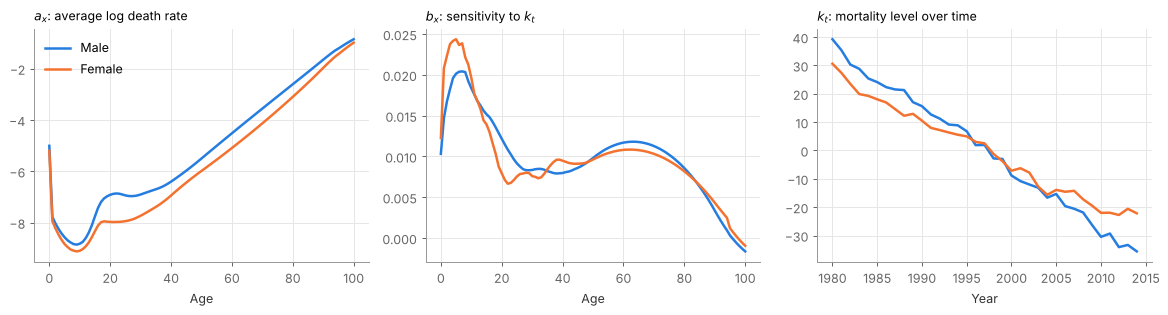

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for s in lc:
    axes[0].plot(lc[s].ages, lc[s].a, color=COLORS[s], label=s.capitalize())
    axes[1].plot(lc[s].ages, lc[s].b, color=COLORS[s])
    axes[2].plot(lc[s].years, lc[s].k, color=COLORS[s])
axes[0].set_title("$a_x$: average log death rate", loc="left", fontsize=10)
axes[1].set_title("$b_x$: sensitivity to $k_t$", loc="left", fontsize=10)
axes[2].set_title("$k_t$: mortality level over time", loc="left", fontsize=10)
axes[0].set_xlabel("Age"); axes[1].set_xlabel("Age"); axes[2].set_xlabel("Year")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/lee_carter_params.png", bbox_inches="tight", dpi=150)

**Reading the parameters**
* $a_x$ has the familiar shape: high infant mortality, a minimum around age 10, then a near-linear (Gompertz) climb.
* $b_x$ peaks in childhood (around age 7) and has a second hump at about 55–75, so the model expects those ages to improve fastest. It is close to zero at 100, because the oldest ages barely improved. Young-adult ages (20–40) carry a moderate $b_x$, so the model keeps forecasting improvement there, but (as notebook 01 showed) young-adult mortality *stopped* improving after about 2010. Lee-Carter has no way to know that.
* $k_t$ falls steadily, which is why a random walk with drift is the standard forecast. The female index flattens after about 2010, an early sign of the slowdown, but the drift is an average over all 35 years, so the forecast doesn't reflect it.

## Backtest: forecast 2015–2024

In [3]:
fc = {s: lc[s].forecast_mx(H) for s in m}
naive = {s: random_walk_forecast(train[s], H) for s in m}

rows = []
for s in m:
    for name, f in [("Lee-Carter", fc[s]), ("Naive trend", naive[s])]:
        rows.append({"sex": s, "model": name,
                     "log RMSE 2015–19": log_rmse(test[s].loc[:, 2015:2019], f.loc[:, 2015:2019]),
                     "log RMSE 2020–24": log_rmse(test[s].loc[:, 2020:2024], f.loc[:, 2020:2024]),
                     "log RMSE all": log_rmse(test[s], f),
                     "MAPE % all": mape(test[s], f)})
scores = pd.DataFrame(rows).set_index(["sex", "model"]).round(3)
scores

log RMSE 2015–19  ...  MAPE % all
sex    model                          ...            
male   Lee-Carter              0.163  ...      17.440
       Naive trend             0.147  ...      16.375
female Lee-Carter              0.115  ...      11.703
       Naive trend             0.084  ...      11.258

[4 rows x 4 columns]

**The naive benchmark slightly beats Lee-Carter** for both sexes and both halves of the window. This is a known weakness: Lee-Carter ties every age to one shared time index, so when different ages go different ways (young adults worsening, older ages improving), it can't follow. The naive model lets each age keep its own trend.

Errors more than double in 2020–2024 for both models, because neither can foresee a pandemic.

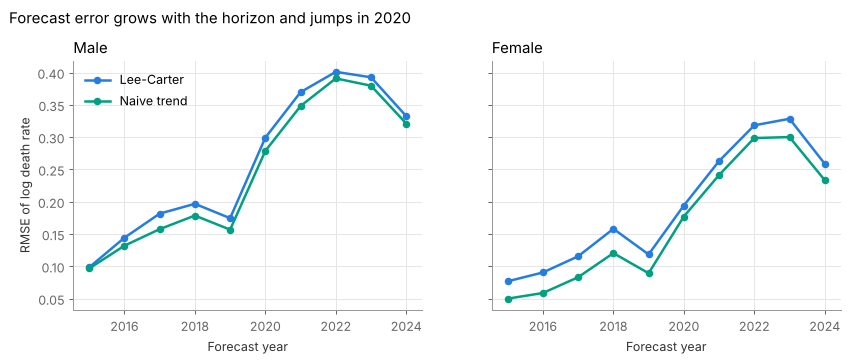

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, s in zip(axes, m):
    for name, f in [("Lee-Carter", fc[s]), ("Naive trend", naive[s])]:
        e = error_by_year(test[s], f)
        ax.plot(e.index, e.values, marker="o", ms=5, color=MODEL_COLORS[name], label=name)
    ax.set_title(s.capitalize(), loc="left"); ax.set_xlabel("Forecast year")
axes[0].set_ylabel("RMSE of log death rate")
axes[0].legend(frameon=False)
fig.suptitle("Forecast error grows with the horizon and jumps in 2020", x=0.06, ha="left", y=1.04)
fig.savefig(f"{FIG_DIR}/backtest_error_by_year.png", bbox_inches="tight", dpi=150)

## Where does the model go wrong? Error by age band

A positive number means the forecast was **too high** (more pessimistic than reality); a negative number means it was **too optimistic**. Values are the average percentage error in death rates.

In [5]:
bands = [(0, 19), (20, 44), (45, 64), (65, 84), (85, 100)]
rows = []
for s in m:
    diff = np.log(fc[s]) - np.log(test[s])
    for period in [(2015, 2019), (2020, 2024)]:
        r = {"sex": s, "years": f"{period[0]}–{period[1]}"}
        for a, b in bands:
            r[f"{a}–{b}"] = (np.exp(diff.loc[a:b, period[0]:period[1]].to_numpy().mean()) - 1) * 100
        rows.append(r)
bias = pd.DataFrame(rows).set_index(["sex", "years"]).round(1)
bias

0–19  20–44  45–64  65–84  85–100
sex    years                                       
male   2015–2019 -13.8  -21.3   -7.4   -0.8     6.0
       2020–2024 -31.8  -41.3  -25.4  -10.6     1.7
female 2015–2019  -7.2  -14.3    2.2    3.3     6.6
       2020–2024 -23.5  -36.2   -7.4   -2.9     3.2

* At ages 20–44 Lee-Carter was far **too optimistic**: before the pandemic it forecast male death rates about 21% below what happened. For a life insurer, mortality that is too optimistic means **term-life premiums that are too low**.
* At ages 85+ it was slightly **too pessimistic**. For annuities and pensions, an error in that direction would overstate how much reserve is needed.
* Errors in opposite directions at different ages can offset in a summary number like life expectancy, which is why I check age bands separately.

## Life expectancy forecast with uncertainty

I turn forecast death rates back into period life expectancy at birth. Ages 101–110 are held at their 2014 values, since they barely affect e0. The shaded band is the 95% interval from the uncertainty in $k_t$ alone. Real uncertainty is wider, because it also comes from the model's structure.

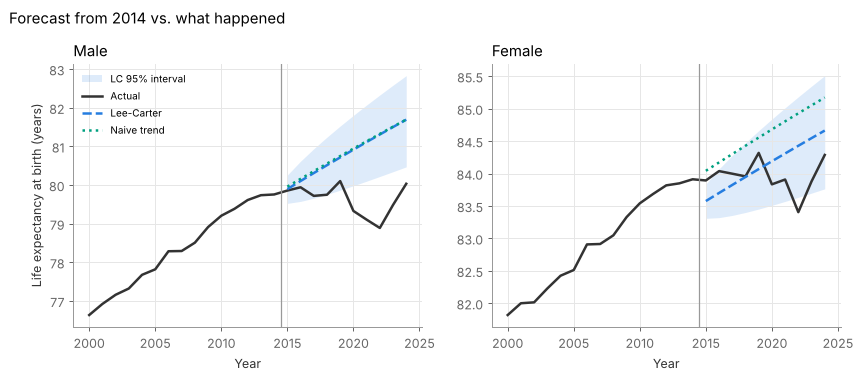

In [6]:
def e0_from_mx(mx_col: pd.Series, tail_q: np.ndarray) -> float:
    return e0(np.concatenate([mx_to_qx(mx_col).to_numpy(), tail_q]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
e0_table = {}
for ax, s in zip(axes, m):
    tail = q_all[s].loc[101:110, TRAIN[1]].to_numpy()
    actual = pd.Series({y: e0(q_all[s][y].to_numpy()) for y in range(2000, 2025)})
    kf = lc[s].forecast_k(H)
    band = {}
    for col in ["k", "lower", "upper"]:
        mx = np.exp(lc[s].a[:, None] + np.outer(lc[s].b, kf[col].to_numpy()))
        band[col] = pd.Series([e0(np.concatenate([mx_to_qx(mx[:, i]), tail])) for i in range(H)], index=kf.index)
    nv = pd.Series({y: e0_from_mx(naive[s][y], tail) for y in naive[s].columns})
    ax.fill_between(band["k"].index, band["upper"], band["lower"], color=MODEL_COLORS["Lee-Carter"], alpha=0.15, lw=0, label="LC 95% interval")
    ax.plot(actual.index, actual.values, color=MODEL_COLORS["Actual"], label="Actual")
    ax.plot(band["k"].index, band["k"].values, color=MODEL_COLORS["Lee-Carter"], ls="--", label="Lee-Carter")
    ax.plot(nv.index, nv.values, color=MODEL_COLORS["Naive trend"], ls=":", label="Naive trend")
    ax.axvline(TRAIN[1] + 0.5, color="#999999", lw=1)
    ax.set_title(s.capitalize(), loc="left"); ax.set_xlabel("Year")
    e0_table[s] = pd.DataFrame({"actual": actual.loc[2015:], "Lee-Carter": band["k"], "LC lower": band["upper"],
                                "LC upper": band["lower"], "Naive trend": nv})
axes[0].set_ylabel("Life expectancy at birth (years)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Forecast from 2014 vs. what happened", x=0.06, ha="left", y=1.04)
fig.savefig(f"{FIG_DIR}/e0_backtest.png", bbox_inches="tight", dpi=150)

In [7]:
pd.concat(e0_table, names=["sex", "year"]).loc[(slice(None), [2015, 2019, 2022, 2024]), :].round(2)

actual  Lee-Carter  LC lower  LC upper  Naive trend
sex    year                                                     
male   2015   79.86       79.90     79.53     80.26        79.96
       2019   80.10       80.72     79.87     81.53        80.75
       2022   78.89       81.31     80.22     82.33        81.32
       2024   80.03       81.69     80.47     82.83        81.70
female 2015   83.89       83.58     83.31     83.84        84.04
       2019   84.32       84.07     83.45     84.66        84.55
       2022   83.41       84.43     83.63     85.18        84.93
       2024   84.29       84.66     83.76     85.51        85.17

* **Men:** by 2017–2018 actual life expectancy was already at the bottom edge of the Lee-Carter 95% interval, and from 2020 to 2024 it was **below the interval every year**. In 2024 the model said 81.7 years; the actual was 80.0. The interval is too narrow because it only counts year-to-year noise in $k_t$, not the chance that the trend itself changes.
* **Women:** the forecast stayed inside the interval in every year except 2015 (when women did slightly *better* than forecast) and 2022 (the pandemic low). By 2024 it is back near the central forecast.

## Why this matters (model risk)
OSFI's Guideline E-23 on model risk management (effective May 2027) expects institutions to validate models, including AI/ML models, against outcomes and to understand their limitations. This backtest is a small example of that: a widely used model looked reasonable in-sample (96% variance explained) but was overconfident out of sample, and the error was concentrated at the ages that matter most for term life pricing.

**Next:** `03_ml_models.ipynb`: gradient boosting on age, year and sex features (and on the Lee-Carter residuals), using the same backtest so the comparison is fair.